# AI Fundamentals: Learning Paradigms, Tasks, and Data Splits

**Learning objective:** recognize common AI task types and learning paradigms, visualize small synthetic examples, and make a safe train/validation/test split.

All data is synthetic and local. No devices, cloud services, APIs, credentials, or GPUs are used.

## Prerequisites

- Read the earlier fundamentals and model/training lessons.
- Know Python variables, lists, dictionaries, functions, and basic plotting.
- NumPy, Matplotlib, and scikit-learn installed in the active notebook kernel.

## Learning objectives

You will compare classification, regression, and clustering; demonstrate simple supervised, unsupervised, semi-supervised, self-supervised, and reinforcement-learning ideas; create train/validation/test splits; plot the examples; validate helper functions; and connect the task choices to synthetic network data.

## Concept: task type and learning paradigm are different questions

**Task type** asks what output is needed: a category (classification), a number (regression), or discovered groups (clustering). **Learning paradigm** asks how useful feedback or targets are provided: labeled examples, unlabeled data, a mixture, targets derived from inputs, or rewards from sequential actions.

```text
Question A: What output do I need? → classification / regression / clustering
Question B: What learning signal do I have? → supervised / unsupervised /
                                             semi-supervised / self-supervised / RL
```

These axes are related but should not be confused.

## Environment and imports

NumPy supplies synthetic numeric arrays; Matplotlib draws graphs; scikit-learn supplies familiar example estimators and data split helpers. We set seeds so the generated examples are repeatable.

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 17
rng = np.random.default_rng(RANDOM_SEED)
print("Random seed:", RANDOM_SEED)
print("NumPy:", np.__version__)
print("scikit-learn imports: ready")

Random seed: 17
NumPy: 2.3.5
scikit-learn imports: ready


**Expected output:** the seed and installed NumPy version followed by `scikit-learn imports: ready`. If an import fails, install the named package in the selected kernel environment and restart the kernel. The seed makes this notebook's generated data and clustering initialization reproducible within the installed library behavior.

## Visual 1 — Classification: predict a category

We create two synthetic features and a two-class target, then fit logistic regression. The goal is to show category prediction, not to build a meaningful incident detector.

In [2]:
healthy_samples = rng.normal(loc=[1.0, 1.0], scale=0.45, size=(40, 2))
warning_samples = rng.normal(loc=[3.0, 3.0], scale=0.45, size=(40, 2))
classification_features = np.vstack([healthy_samples, warning_samples])
classification_labels = np.array([0] * len(healthy_samples) + [1] * len(warning_samples))

classifier = LogisticRegression(random_state=RANDOM_SEED)
classifier.fit(classification_features, classification_labels)
class_predictions = classifier.predict(classification_features)

print("Feature array shape:", classification_features.shape)
print("Label values:", np.unique(classification_labels).tolist())
print("Training accuracy (teaching demo):", round(float(np.mean(class_predictions == classification_labels)), 2))
assert classification_features.shape == (80, 2)
assert set(class_predictions) == {0, 1}

Feature array shape: (80, 2)
Label values: [0, 1]
Training accuracy (teaching demo): 1.0


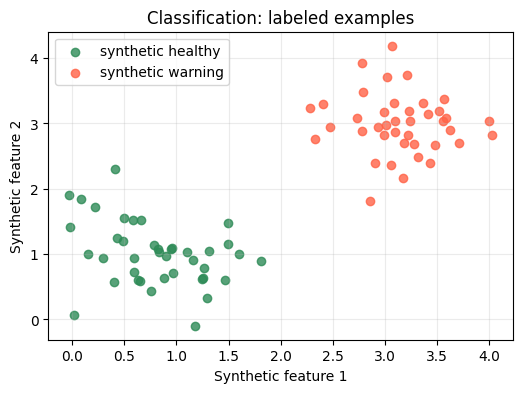

In [3]:
plt.figure(figsize=(6, 4))
for label, color, name in [(0, "seagreen", "synthetic healthy"), (1, "tomato", "synthetic warning")]:
    selected = classification_labels == label
    plt.scatter(
        classification_features[selected, 0],
        classification_features[selected, 1],
        color=color,
        label=name,
        alpha=0.8,
    )
plt.title("Classification: labeled examples")
plt.xlabel("Synthetic feature 1")
plt.ylabel("Synthetic feature 2")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Interpret the classification graph

- **X/Y axes:** two invented numeric features; they are not real counters.
- **Points:** one synthetic example each.
- **Colors:** supplied target categories, green for class 0 and red for class 1.
- **Pattern:** the two classes were generated around different centers, so they are intentionally easy to separate.
- **Useful for:** seeing what labeled classification data looks like.
- **Do not conclude:** that real network states form these tidy groups, or that training accuracy predicts future performance.

## Visual 2 — Regression: predict a number

Regression predicts a numeric value. Here we construct a simple synthetic relationship between utilization and latency, add small noise, and fit a line.

In [4]:
utilization = np.linspace(10, 90, 35)
latency_ms = 8 + 0.55 * utilization + rng.normal(0, 3, size=len(utilization))
regression_features = utilization.reshape(-1, 1)
regressor = LinearRegression().fit(regression_features, latency_ms)
predicted_latency = regressor.predict(regression_features)

print("Regression output type: numeric")
print("Learned slope:", round(float(regressor.coef_[0]), 2))
print("First three predicted values:", np.round(predicted_latency[:3], 2).tolist())
assert len(predicted_latency) == len(latency_ms)

Regression output type: numeric
Learned slope: 0.56
First three predicted values: [13.15, 14.46, 15.77]


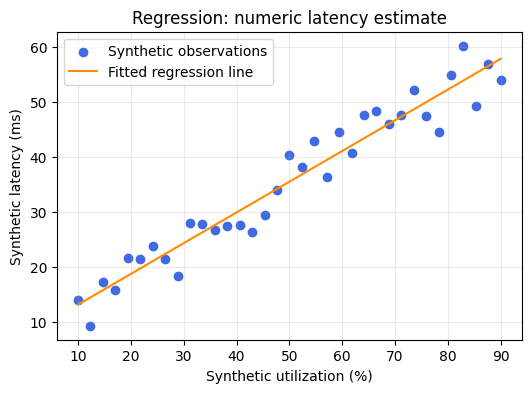

In [5]:
plt.figure(figsize=(6, 4))
plt.scatter(utilization, latency_ms, color="royalblue", label="Synthetic observations")
plt.plot(utilization, predicted_latency, color="darkorange", label="Fitted regression line")
plt.title("Regression: numeric latency estimate")
plt.xlabel("Synthetic utilization (%)")
plt.ylabel("Synthetic latency (ms)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Interpret the regression graph

- **X-axis:** invented utilization percentage.
- **Y-axis:** invented latency in milliseconds.
- **Blue points:** generated observations with noise.
- **Orange line:** model's numeric predictions.
- **Pattern:** the constructed data generally rises with utilization.
- **Useful for:** distinguishing a numeric prediction from a category.
- **Do not conclude:** that utilization alone causes latency in real networks or that extrapolating this line is safe.

## Visual 3 — Clustering: discover groups without labels

For clustering, the fitting algorithm receives feature points but no class labels. K-means assigns points to a chosen number of groups based on distances to cluster centers. Here we use the same two synthetic clouds but deliberately hide their original labels from the algorithm.

In [6]:
clusterer = KMeans(n_clusters=2, random_state=RANDOM_SEED, n_init=10)
cluster_ids = clusterer.fit_predict(classification_features)
print("Cluster IDs produced:", np.unique(cluster_ids).tolist())
print("Cluster sizes:", np.bincount(cluster_ids).tolist())
assert len(cluster_ids) == len(classification_features)

Cluster IDs produced: [0, 1]
Cluster sizes: [40, 40]


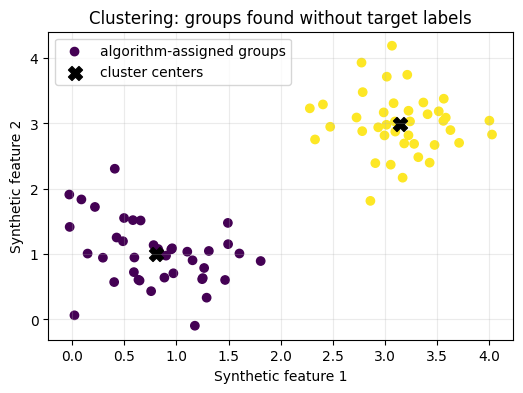

In [7]:
plt.figure(figsize=(6, 4))
plt.scatter(
    classification_features[:, 0],
    classification_features[:, 1],
    c=cluster_ids,
    cmap="viridis",
    label="algorithm-assigned groups",
)
plt.scatter(
    clusterer.cluster_centers_[:, 0],
    clusterer.cluster_centers_[:, 1],
    color="black",
    marker="X",
    s=100,
    label="cluster centers",
)
plt.title("Clustering: groups found without target labels")
plt.xlabel("Synthetic feature 1")
plt.ylabel("Synthetic feature 2")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Interpret the clustering graph

The colors are cluster IDs created by K-means, not the original healthy/warning labels. Black X markers show learned centers. Cluster ID numbers are arbitrary and can swap between runs or settings. Clustering is useful for exploration, but people must validate whether groups are meaningful. A group is not automatically a root cause.

## Semi-supervised learning: keep the unlabeled examples distinct

Semi-supervised learning uses some labeled examples and some unlabeled examples. This tiny demonstration splits synthetic records into a labeled subset and an unlabeled subset; it does not pretend that the unlabeled records have known answers.

In [8]:
labeled_count = 12
labeled_features = classification_features[:labeled_count]
labeled_targets = classification_labels[:labeled_count]
unlabeled_features = classification_features[labeled_count:]

print("Labeled examples:", len(labeled_features))
print("Unlabeled examples:", len(unlabeled_features))
print("Targets are available only for labeled rows:", len(labeled_targets) == len(labeled_features))
assert len(labeled_features) + len(unlabeled_features) == len(classification_features)

Labeled examples: 12
Unlabeled examples: 68
Targets are available only for labeled rows: True


This cell shows the data ingredients, not a complete semi-supervised algorithm. Real methods make assumptions about how unlabeled examples relate to labeled examples. Compare them using a separate reviewed test set; do not treat inferred labels as ground truth.

## Self-supervised learning: derive a target from the input

A self-supervised exercise can hide the next token in a sequence and use that token as the target. This toy data preparation step illustrates where labels can come from without manual annotation; it does not train a language model.

In [9]:
def make_next_token_examples(tokens: list[str]) -> list[dict[str, str]]:
    """Pair each token prefix with the next token as a self-supervised target."""
    if len(tokens) < 2:
        raise ValueError("at least two tokens are required")
    return [
        {"input_context": " ".join(tokens[:index]), "target_next_token": tokens[index]}
        for index in range(1, len(tokens))
    ]

event_tokens = ["BGP", "neighbor", "down", "on", "edge-router"]
next_token_examples = make_next_token_examples(event_tokens)
for example in next_token_examples:
    print(example)
assert next_token_examples[0] == {"input_context": "BGP", "target_next_token": "neighbor"}

{'input_context': 'BGP', 'target_next_token': 'neighbor'}


{'input_context': 'BGP neighbor', 'target_next_token': 'down'}
{'input_context': 'BGP neighbor down', 'target_next_token': 'on'}
{'input_context': 'BGP neighbor down on', 'target_next_token': 'edge-router'}


Each row's input is the preceding token prefix; its target is the next token taken from the original sequence. Real language-model training uses far larger datasets, tokenization, model architectures, and optimization. The method does not guarantee source text is correct or safe to use.

## Reinforcement learning: a tiny isolated reward example

An agent observes a state, chooses an action, and receives reward feedback. This simple one-step simulation compares two abstract actions. It does not connect to a network or learn a robust policy; it only makes the reward idea concrete.

In [10]:
simulated_actions = {
    "inspect_read_only_counters": 2,
    "make_unapproved_change": -100,
}
chosen_action = max(simulated_actions, key=simulated_actions.get)
received_reward = simulated_actions[chosen_action]

print("Simulated state:", "link alert requires investigation")
print("Chosen abstract action:", chosen_action)
print("Simulated reward:", received_reward)
assert chosen_action == "inspect_read_only_counters"

Simulated state: link alert requires investigation
Chosen abstract action: inspect_read_only_counters
Simulated reward: 2


Here the action values are manually specified, so this is **not training an RL agent**. It demonstrates that rewards encode preferences, and that bad reward design could encourage bad behavior. Real network actions must be constrained and approved; never let a learner explore changes on production devices.

## Train, validation, and test: separate the roles

Training data fits parameters. Validation data guides development choices. Test data should be reserved for the final evaluation after choices are settled. Stratification preserves approximate class ratios in each split for this simple independent synthetic dataset.

In [11]:
features_train, features_remaining, labels_train, labels_remaining = train_test_split(
    classification_features,
    classification_labels,
    test_size=0.40,
    random_state=RANDOM_SEED,
    stratify=classification_labels,
)
features_validation, features_test, labels_validation, labels_test = train_test_split(
    features_remaining,
    labels_remaining,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=labels_remaining,
)

split_counts = {
    "train": len(labels_train),
    "validation": len(labels_validation),
    "test": len(labels_test),
}
print("Split sizes:", split_counts)
print("Train class counts:", np.bincount(labels_train).tolist())
print("Validation class counts:", np.bincount(labels_validation).tolist())
print("Test class counts:", np.bincount(labels_test).tolist())
assert sum(split_counts.values()) == len(classification_labels)
assert not (set(map(tuple, features_train)) & set(map(tuple, features_test)))

Split sizes: {'train': 48, 'validation': 16, 'test': 16}
Train class counts: [24, 24]
Validation class counts: [8, 8]
Test class counts: [8, 8]


The code first assigns 60% to training and 40% to a temporary remainder. It then splits that remainder evenly, yielding 60% training, 20% validation, and 20% test. Stratification keeps the two synthetic classes represented. The disjointness assertion checks that identical feature rows were not copied across train and test in this generated sample.

For time-ordered syslogs, this random split may be inappropriate: use earlier time periods for training and later periods for validation/test. For repeated devices or incidents, consider group-based splitting to keep related records together.

## Train, choose, and evaluate with distinct data

We fit a model on training data, inspect validation accuracy during development, then show the test result once as the final demonstration. In a real workflow, avoid repeatedly checking the test set while changing the model.

In [12]:
split_classifier = LogisticRegression(random_state=RANDOM_SEED)
split_classifier.fit(features_train, labels_train)
validation_accuracy = float(np.mean(split_classifier.predict(features_validation) == labels_validation))
final_test_accuracy = float(np.mean(split_classifier.predict(features_test) == labels_test))

print("Validation accuracy (development check):", round(validation_accuracy, 2))
print("Test accuracy (final demo check):", round(final_test_accuracy, 2))
assert 0 <= validation_accuracy <= 1
assert 0 <= final_test_accuracy <= 1

Validation accuracy (development check): 1.0
Test accuracy (final demo check): 1.0


Accuracy is the fraction of examples predicted correctly. These synthetic classes were deliberately easy to separate, and this is a tiny dataset; the scores should not be generalized to real network data. Later lessons will cover confusion matrices, precision, recall, F1, class imbalance, and overfitting.

## Network example: choose an appropriate task

Classify the requested output before selecting a method:

| Network question | Output type | Candidate task | Important caution |
|---|---|---|---|
| Is this synthetic event `BGP`, `interface`, or `power` related? | Category | Classification | Categories need consistent reviewed labels. |
| What numeric utilization might occur next interval? | Number | Regression / forecasting | Time ordering and drift matter. |
| Which unlabeled telemetry records look alike? | Groups | Clustering | Similarity groups are not diagnoses. |
| Which approved read-only query should be inspected next in a simulation? | Sequential choice | Possibly RL, often a workflow first | Never explore unsafe changes in production. |

The feature set, label quality, error costs, and safety boundaries matter as much as the algorithm name.

## Common errors and debugging

- **Wrong output type:** trying to use regression for categories or classification for a continuous measurement. Start by naming the target and its type.
- **Label/feature length mismatch:** each labeled feature row needs one target. Check row counts before fitting.
- **Training/test contamination:** fitting preprocessing on all data or tuning against test examples makes evaluation optimistic. Fit transformations on training data only and preserve test data.
- **Class missing in a split:** very small or imbalanced data may not support stratification. Gather more reviewed examples or revise the evaluation design; do not silently remove a class.
- **Scaling changes cluster results:** distance-based methods can be dominated by larger-scale features. Consider training-only scaling, inspect units, and compare carefully.
- **Misread cluster IDs:** numeric cluster IDs are identifiers, not ordered severity values.
- **Unsafe RL exploration:** reward-driven trial and error can cause harm. Keep demonstrations simulated; constrain and approve any real action.

The notebook avoids broad exception handling so unexpected failures remain visible.

## Practice exercises

### Beginner
1. Decide whether predicting an incident category is classification or regression.
2. Change `n_clusters` to `3`; compare cluster sizes and explain why this is a choice, not a discovered fact.
3. Add one sentence to the next-token example explaining how its target was derived.

### Intermediate
4. Change the train/validation/test percentages to 70/15/15 and verify the counts sum to the dataset size.
5. Create a time-ordered split by using the first 60% of rows for training, the next 20% for validation, and the last 20% for test. Explain why this can be more appropriate for logs.

### Advanced
6. Fit a `StandardScaler` using only `features_train`, then use that scaler to transform train, validation, and test features. Explain what leakage this avoids.

### Network automation
7. Create synthetic event dictionaries with timestamp and one reviewed category. Split by incident ID so records from one incident cannot occur in both training and test. Print the unique incident IDs per split and verify disjointness.

## Exercise solutions

Run after attempting the exercises. The examples are local and synthetic.

In [13]:
# 1
print("1: incident category is classification")

# 2
three_group_model = KMeans(n_clusters=3, random_state=RANDOM_SEED, n_init=10)
three_group_ids = three_group_model.fit_predict(classification_features)
print("2 cluster sizes:", np.bincount(three_group_ids).tolist())

# 3
print("3: each next-token target is taken from the original sequence after its input prefix.")

# 4
x_train_70, x_rest_30, y_train_70, y_rest_30 = train_test_split(
    classification_features, classification_labels, test_size=0.30,
    random_state=RANDOM_SEED, stratify=classification_labels,
)
x_val_15, x_test_15, y_val_15, y_test_15 = train_test_split(
    x_rest_30, y_rest_30, test_size=0.50,
    random_state=RANDOM_SEED, stratify=y_rest_30,
)
print("4 split counts:", len(y_train_70), len(y_val_15), len(y_test_15))
assert len(y_train_70) + len(y_val_15) + len(y_test_15) == len(classification_labels)

# 5
row_order = np.arange(len(classification_features))
train_end = int(0.60 * len(row_order))
validation_end = int(0.80 * len(row_order))
time_order_train = row_order[:train_end]
time_order_validation = row_order[train_end:validation_end]
time_order_test = row_order[validation_end:]
assert max(time_order_train) < min(time_order_validation) < min(time_order_test)
print("5 time-ordered row ranges:", (int(time_order_train[0]), int(time_order_train[-1])), (int(time_order_validation[0]), int(time_order_validation[-1])), (int(time_order_test[0]), int(time_order_test[-1])))

# 6
scaler = StandardScaler().fit(features_train)
scaled_train = scaler.transform(features_train)
scaled_validation = scaler.transform(features_validation)
scaled_test = scaler.transform(features_test)
print("6 scaled shapes:", scaled_train.shape, scaled_validation.shape, scaled_test.shape)

# 7
incident_ids = np.repeat(np.arange(10), 3)
unique_incidents = np.unique(incident_ids)
incident_train, incident_rest = train_test_split(
    unique_incidents, test_size=0.4, random_state=RANDOM_SEED
)
incident_validation, incident_test = train_test_split(
    incident_rest, test_size=0.5, random_state=RANDOM_SEED
)
print("7 incident IDs by split:", incident_train.tolist(), incident_validation.tolist(), incident_test.tolist())
assert not (set(incident_train) & set(incident_validation))
assert not (set(incident_train) & set(incident_test))
assert not (set(incident_validation) & set(incident_test))

1: incident category is classification
2 cluster sizes: [28, 40, 12]
3: each next-token target is taken from the original sequence after its input prefix.
4 split counts: 56 12 12
5 time-ordered row ranges: (0, 47) (48, 63) (64, 79)
6 scaled shapes: (48, 2) (16, 2) (16, 2)
7 incident IDs by split: [4, 0, 9, 8, 6, 1] [2, 3] [7, 5]


### Solution notes

A category is classification. Choosing three clusters forces an algorithm setting; it does not prove three natural groups exist. The 70/15/15 split keeps rows disjoint. Time-ordered evaluation tests later examples using earlier examples for training. Scaling is fitted only on training features, preventing validation/test statistics from influencing the transformation. Grouping by incident ID keeps related records together; a production pipeline should split actual complete groups, not merely row indices.

## Mini-project: map network questions to learning setups

Complete a tiny decision table programmatically. This is a teaching aid, not an automatic model selector.

In [14]:
network_task_map = [
    {"question": "Classify a reviewed syslog category", "output": "category", "candidate_task": "supervised classification"},
    {"question": "Estimate next interval utilization", "output": "number", "candidate_task": "supervised regression / forecasting"},
    {"question": "Explore groups in unlabeled telemetry", "output": "groups", "candidate_task": "unsupervised clustering"},
    {"question": "Predict next token in synthetic event text", "output": "token", "candidate_task": "self-supervised target construction"},
]
for task in network_task_map:
    print(f"{task['output']:>8} | {task['candidate_task']:<42} | {task['question']}")
assert len(network_task_map) == 4

category | supervised classification                  | Classify a reviewed syslog category
  number | supervised regression / forecasting        | Estimate next interval utilization
  groups | unsupervised clustering                    | Explore groups in unlabeled telemetry
   token | self-supervised target construction        | Predict next token in synthetic event text


The mini-project makes task selection explicit: state the question, output type, and candidate learning setup before choosing software. For a real case, add data availability, evaluation metric, error impact, time/group constraints, and safety controls.

## Key takeaways

1. Classification outputs categories; regression outputs numbers; clustering discovers groups.
2. Supervised methods learn from provided input/target pairs.
3. Unsupervised methods explore structure without supplied target labels.
4. Semi-supervised learning uses both labeled and unlabeled examples; self-supervised targets are derived from inputs.
5. Reinforcement learning uses actions and reward over time; keep infrastructure examples simulated and safe.
6. Training, validation, and test sets serve different purposes.
7. Time- or incident-related records often need time/group-aware splits.
8. Synthetic plots build intuition but cannot establish operational validity.

## Restart Kernel and Run All verification checklist

- [ ] Select the intended Python kernel and restart it.
- [ ] Run every cell from top to bottom.
- [ ] Confirm the classification, regression, and clustering plots render with axis labels and legends.
- [ ] Confirm the semi-supervised example has both labeled and unlabeled records.
- [ ] Confirm self-supervised examples derive each target from the token sequence.
- [ ] Confirm the RL illustration remains a local simulation and selects the read-only abstract action.
- [ ] Confirm train/validation/test sizes sum to the full dataset and the final test set is separate.
- [ ] Confirm exercise solution assertions pass, including group split disjointness.
- [ ] Confirm no cell accesses a network device or external service.

**Completion summary:** this notebook demonstrates learning paradigms, task types, visual data patterns, safe synthetic networking analogies, and evaluation data separation.